In [1]:
import os
import random
import numpy as np
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import torch.nn as nn
import matplotlib.pyplot as plt
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)

cuda


In [2]:
# Bangla Sign Language dataset (RSBdSL38), random split: train / val / test
data_root = '/kaggle/input/datasets/swadhinrispro/signed-dataset/RSBdSL38-v1/RSBdSL38'
print(os.listdir(data_root))

['test', 'train', 'val']


In [ ]:
import torchvision.transforms as transforms
IMG_SIZE = 256
MEAN = [0.5, 0.5, 0.5]
STD = [0.5, 0.5, 0.5]


train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),   
    transforms.ToTensor(),                    
    transforms.Normalize(MEAN, STD),           
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(), #0-1
    transforms.Normalize(MEAN, STD),
])

train_folder = data_root + '/train'
val_folder = data_root + '/val'
test_folder = data_root + '/test'

train_data = datasets.ImageFolder(train_folder, transform=train_transform)
val_data = datasets.ImageFolder(val_folder, transform=val_transform)
test_data = datasets.ImageFolder(test_folder, transform=val_transform)
print(f"Trn:{len(train_data)}")
print(f"Val:{len(val_data)}")
print(f"Tst:{len(test_data)}")
class_names = train_data.classes   
class_names

Trn:8685
Val:1086
Tst:1103


['0',
 '1',
 '10',
 '11',
 '12',
 '13',
 '14',
 '15',
 '16',
 '17',
 '18',
 '19',
 '2',
 '20',
 '21',
 '22',
 '23',
 '24',
 '25',
 '26',
 '27',
 '28',
 '29',
 '3',
 '30',
 '31',
 '32',
 '33',
 '34',
 '35',
 '36',
 '37',
 '4',
 '5',
 '6',
 '7',
 '8',
 '9']

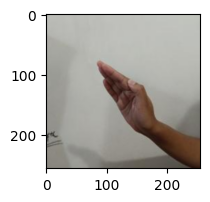

In [ ]:
def denorm(t):
  
    mean = torch.tensor(MEAN).view(3, 1, 1)
    std = torch.tensor(STD).view(3, 1, 1)
    return (t.cpu() * std + mean).clamp(0, 1)

plt.figure(figsize = (2,2))
plt.imshow(denorm(train_data[800][0]).permute(1,2,0))

In [ ]:

batch_size = 32
learning_rate=0.001
minimum_learning_rate=1e-5
weight_decay=1e-4
epochs = 50

In [6]:
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True,num_workers=4, pin_memory=True)
val_loader = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
test_loader = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)

In [ ]:
from torch.optim import AdamW
from torch.optim.lr_scheduler import CosineAnnealingLR

def conv_block(in_ch, out_ch):
    return nn.Sequential(
        nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
        nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
        nn.BatchNorm2d(out_ch),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )

class CNNModel(nn.Module):
    def __init__(self, num_classes=38):
        super(CNNModel, self).__init__()

       
        self.conv_layers = nn.Sequential(
            conv_block(3, 32),        # 3x256x256 -> 32x128x128
            conv_block(32, 64),       # 64x64x64
            conv_block(64, 128),      # 128x32x32
            conv_block(128, 256),     # 256x16x16
            conv_block(256, 256),     # 256x8x8
            nn.AdaptiveAvgPool2d(1),  # 256x1x1
        )

        # Fully connected layers/Classification Head/ANN
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

#1. Get the Model
model = CNNModel(num_classes=len(class_names)).to(device)
# 2. Define optimizer
optimizer = AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
# 3. Define LR scheduler
scheduler = CosineAnnealingLR(optimizer, T_max=epochs, eta_min=minimum_learning_rate)
# 4. Define loss function
criterion = nn.CrossEntropyLoss(label_smoothing=0.05)
# 5. Mixed precision
use_amp = device == 'cuda'
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

from torchsummary import summary
summary(model, input_size=(3,IMG_SIZE,IMG_SIZE));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 256, 256]             864
       BatchNorm2d-2         [-1, 32, 256, 256]              64
              ReLU-3         [-1, 32, 256, 256]               0
            Conv2d-4         [-1, 32, 256, 256]           9,216
       BatchNorm2d-5         [-1, 32, 256, 256]              64
              ReLU-6         [-1, 32, 256, 256]               0
         MaxPool2d-7         [-1, 32, 128, 128]               0
            Conv2d-8         [-1, 64, 128, 128]          18,432
       BatchNorm2d-9         [-1, 64, 128, 128]             128
             ReLU-10         [-1, 64, 128, 128]               0
           Conv2d-11         [-1, 64, 128, 128]          36,864
      BatchNorm2d-12         [-1, 64, 128, 128]             128
             ReLU-13         [-1, 64, 128, 128]               0
        MaxPool2d-14           [-1, 64,

In [8]:
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    total_loss = 0
    correct = 0
    total = 0
    for images, labels in loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        optimizer.zero_grad()

        total_loss += loss.item()

        # compute accuracy
        _, preds = torch.max(outputs, 1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    train_loss = total_loss / len(loader)
    train_acc = correct / total

    return train_loss, train_acc

def validate_epoch(model, loader, criterion, device):

    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    val_loss = total_loss / len(loader)
    val_acc = correct / total

    return val_loss, val_acc

In [ ]:
train_losses = []
train_accuracies = []
val_losses = []
val_accuracies = []
best_val_acc = 0.0

for epoch in range(epochs):
    print(f"----------------------------------------------------")
    print(f"Epoch {epoch+1}/{epochs}, LR: {optimizer.param_groups[0]['lr']:.6g}")

    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion, device)
    val_loss, val_acc = validate_epoch(model, val_loader, criterion, device)
    scheduler.step()

    train_losses.append(train_loss)
    train_accuracies.append(train_acc)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.4f}")


    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), 'best.pt')
        print(f"  saved new best model (val acc {val_acc:.4f})")

print('Best validation accuracy:', round(best_val_acc, 4))

----------------------------------------------------
Epoch 1/50, LR: 0.001
Train Loss: 3.6455 | Train Acc: 0.0260
Val Loss: 3.6531 | Val Acc: 0.0359
  saved new best model (val acc 0.0359)
----------------------------------------------------
Epoch 2/50, LR: 0.000999023
Train Loss: 3.6368 | Train Acc: 0.0274
Val Loss: 3.6335 | Val Acc: 0.0322
----------------------------------------------------
Epoch 3/50, LR: 0.000996097
Train Loss: 3.6344 | Train Acc: 0.0265
Val Loss: 3.6328 | Val Acc: 0.0304
----------------------------------------------------
Epoch 4/50, LR: 0.000991232
Train Loss: 3.6339 | Train Acc: 0.0283
Val Loss: 3.6323 | Val Acc: 0.0331
----------------------------------------------------
Epoch 5/50, LR: 0.000984449
Train Loss: 3.6310 | Train Acc: 0.0309
Val Loss: 3.6354 | Val Acc: 0.0285
----------------------------------------------------
Epoch 6/50, LR: 0.000975773
Train Loss: 3.5890 | Train Acc: 0.0402
Val Loss: 3.5012 | Val Acc: 0.0562
  saved new best model (val acc 0.05

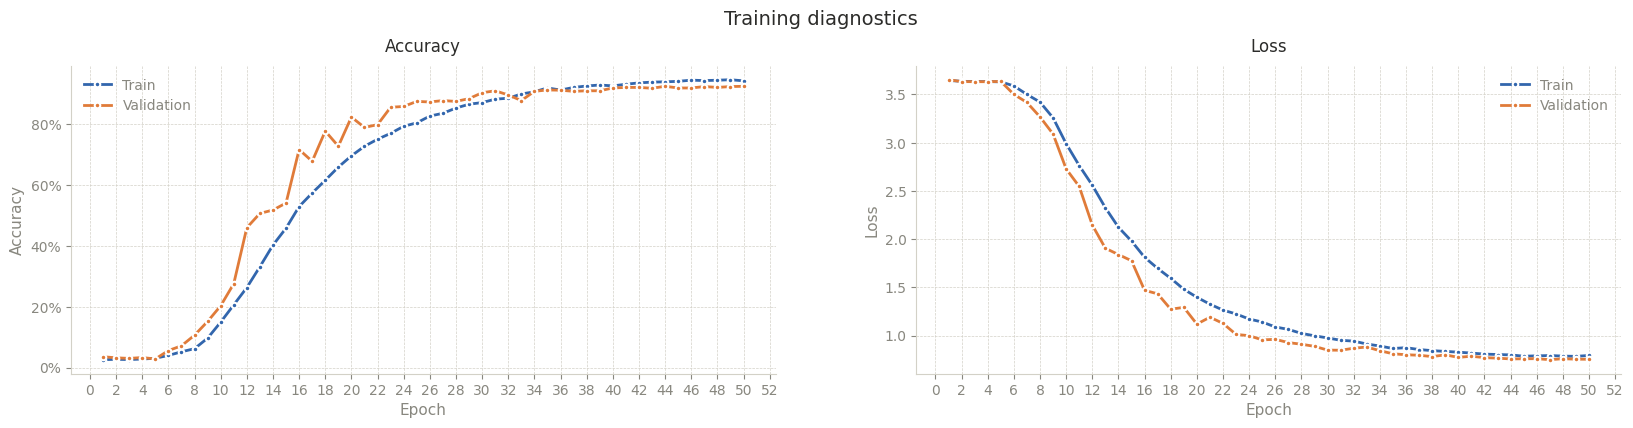

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import numpy as np

BLUE   = "#3266ad"
ORANGE = "#e07b39"
GRAY   = "#88877f"

plt.rcParams.update({
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#d3d1c7",
    "axes.linewidth": 0.8,
    "axes.grid": True,
    "grid.color": "#d3d1c7",
    "grid.linewidth": 0.5,
    "grid.linestyle": "--",
    "xtick.color": GRAY,
    "ytick.color": GRAY,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

epochs_number = np.arange(1, epochs + 1)
fig = plt.figure(figsize=(20, 4))
gs  = gridspec.GridSpec(1, 2, figure=fig, wspace=0.2)

# ── Accuracy ──────────────────────────────────────────────────────────────────
ax1 = fig.add_subplot(gs[0])
ax1.plot(epochs_number, train_accuracies, color=BLUE,   lw=2,   label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax1.plot(epochs_number, val_accuracies,   color=ORANGE, lw=2,   label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-")
ax1.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{x*100:.0f}%"))
ax1.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax1.set_ylabel("Accuracy", color=GRAY, fontsize=11)
ax1.set_title("Accuracy", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax1.legend(frameon=False, fontsize=10, labelcolor=GRAY)

# ── Loss ──────────────────────────────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1])
ax2.plot(epochs_number, train_losses, color=BLUE,   lw=2, label="Train",      marker="o", ms=4, mew=1.5, mec="white")
ax2.plot(epochs_number, val_losses,   color=ORANGE, lw=2, label="Validation", marker="o", ms=4, mew=1.5, mec="white", linestyle="-")
ax2.xaxis.set_major_locator(mticker.MultipleLocator(2))
ax2.set_xlabel("Epoch", color=GRAY, fontsize=11)
ax2.set_ylabel("Loss",  color=GRAY, fontsize=11)
ax2.set_title("Loss", fontsize=12, fontweight="medium", color="#2c2c2a", pad=10)
ax2.legend(frameon=False, fontsize=10, labelcolor=GRAY)

fig.suptitle("Training diagnostics", fontsize=14, fontweight="medium", color="#2c2c2a", y=1.02)
plt.savefig("training_curves.pdf", bbox_inches="tight", dpi=150)
plt.show()

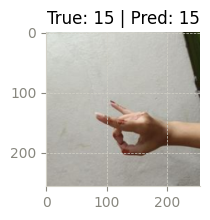

In [19]:
ix = torch.randint(0,len(test_data),())
img = test_data[ix][0].unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    np_output = model(img).float().cpu().numpy()
pred = np.exp(np_output)/np.sum(np.exp(np_output))
plt.figure(figsize=(2,2))
plt.imshow(denorm(img.squeeze(0)).permute(1,2,0).numpy())
plt.title(f"True: {class_names[test_data[ix][1]]} | Pred: {class_names[pred[0].argmax()]}")
plt.show()

Total misclassified samples: 96


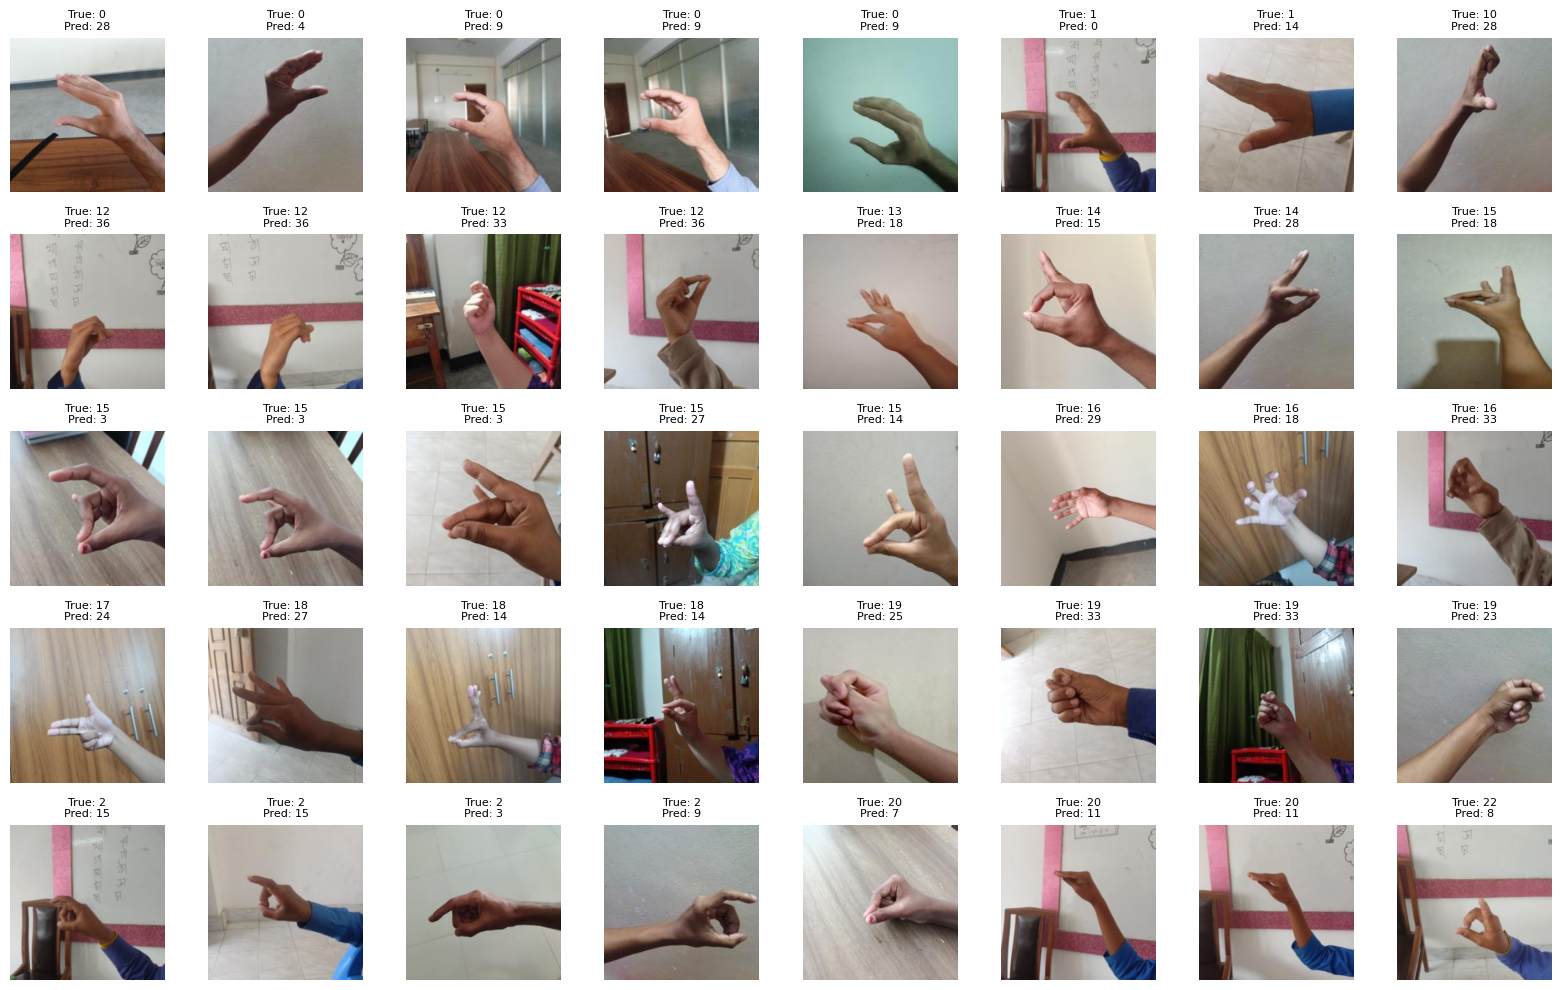

In [ ]:
import torch
import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix
import seaborn as sns

class_names = test_data.classes  

model.eval()
misclassified = []
all_preds = []
all_labels = []


with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        with torch.autocast(device_type=device, dtype=torch.float16, enabled=use_amp):
            outputs = model(images)
        _, preds = torch.max(outputs, 1)

        # Save all predictions and labels for confusion matrix
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

        # Store misclassified images
        for img, true, pred in zip(images, labels, preds):
            if true != pred:
                misclassified.append((img.cpu(), true.cpu(), pred.cpu()))

print(f"Total misclassified samples: {len(misclassified)}")


num_rows = 5
num_cols = 8
num_to_show = num_rows * num_cols
num_to_show = min(num_to_show, len(misclassified))

fig, axes = plt.subplots(num_rows, num_cols, figsize=(num_cols*2, num_rows*2))
axes = axes.flatten()  

for idx in range(num_to_show):
    img, true, pred = misclassified[idx]
    img = denorm(img).permute(1, 2, 0)  
    img = (img * 255).numpy().astype(np.uint8)

    axes[idx].imshow(img)
    axes[idx].set_title(f"True: {class_names[true]}\nPred: {class_names[pred]}", fontsize=8)
    axes[idx].axis('off')

for idx in range(num_to_show, len(axes)):
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

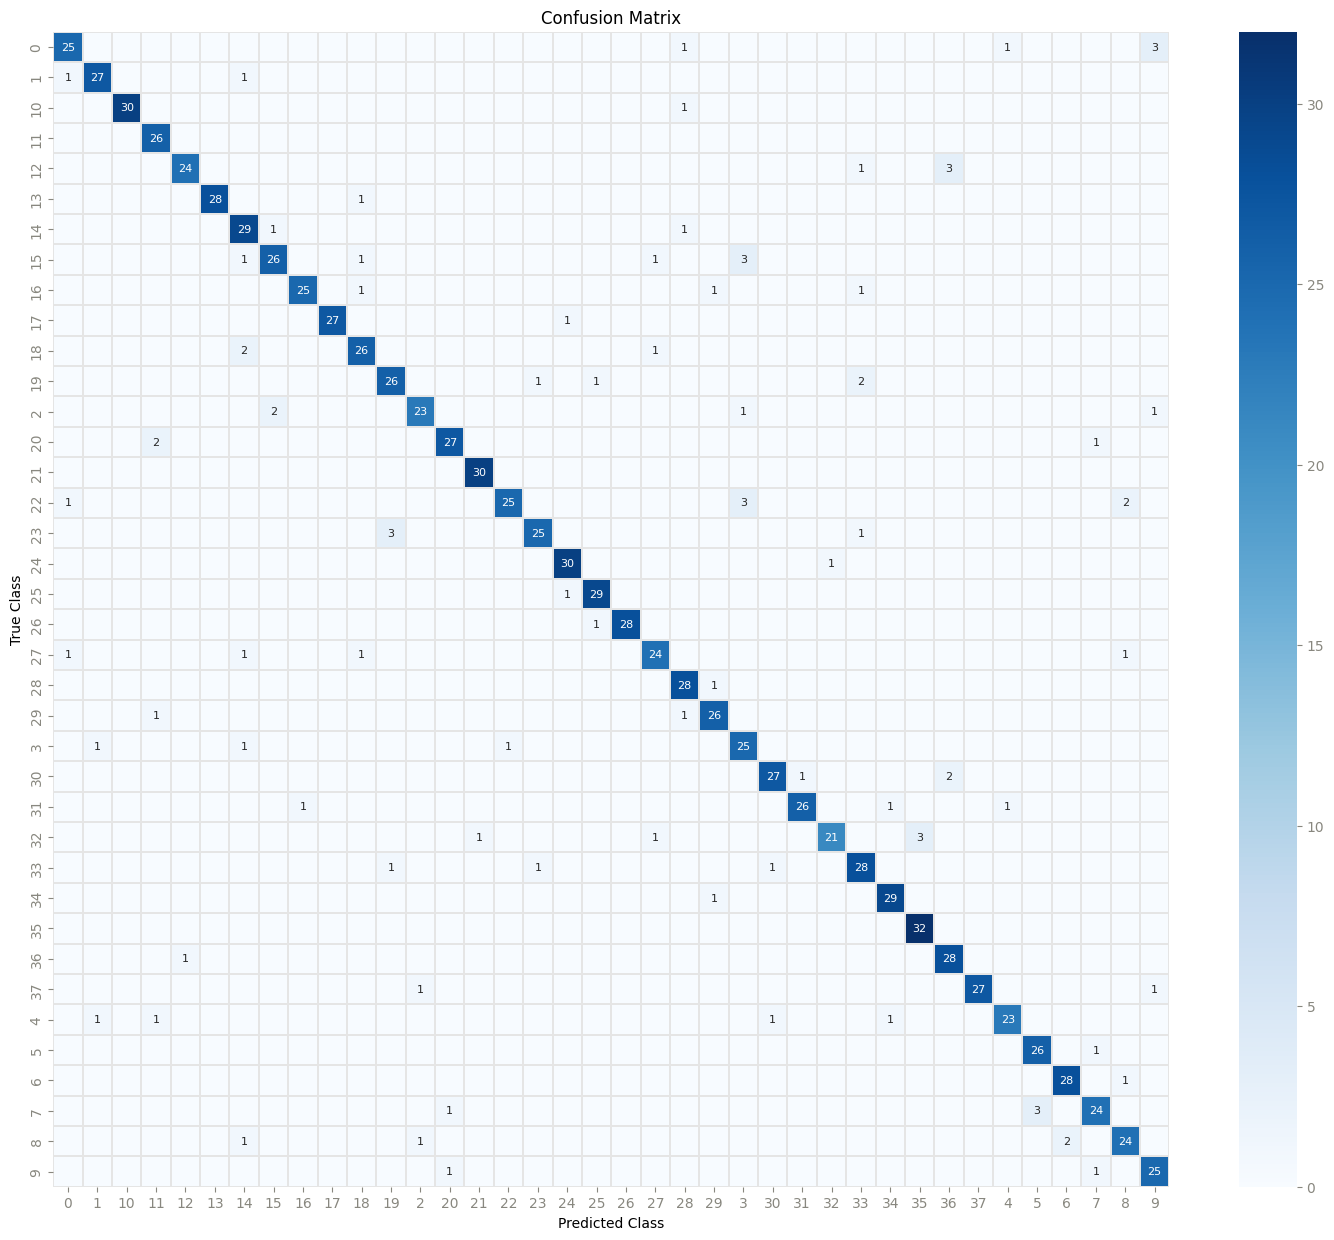

In [ ]:
#Confusion Matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(18,15))
annot = np.where(cm > 0, cm.astype(str), "")   
ax = sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', annot_kws={"size": 8},
            xticklabels=class_names, yticklabels=class_names, linewidths=0.3, linecolor='#e5e5e5')
ax.grid(False)   
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("Confusion Matrix")
plt.show()